<a href="https://colab.research.google.com/github/chantellehendry12-byte/Colab/blob/Colab/CA2_Outpatient_Waiting_List_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**OUTPATIENT WAITING LIST TRENDS IN IRISH PUBLIC HOSPITALS (2022-2025)**

*ANAL_IT705 - Data Analytics & Visualisation - CA2*

# Outpatient Waiting List Trends in Irish Public Hospitals (2022–2025)

*ANAL_IT705 – Data Analytics & Visualisation – CA2*

## 1. INTRODUCTION

Outpatient waiting times remain an important issue within Ireland's public healthcare system. While the total number of patients on waiting lists is frequently reported, this figure alone does not indicate how long patients have been waiting for appointments.

The aim of this project is to analyse outpatient waiting-list trends in Irish public hospitals between January 2022 and December 2025, using publicly available data from the National Treatment Purchase Fund (NTPF).

The analysis will examine changes in overall waiting-list numbers and the distribution of patients across different waiting-time categories, with particular attention given to those waiting 12 months or longer. Comparisons will also be made between hospitals, medical specialities and adult and child waiting lists.

**Research question:** How did the size and waiting-time profile of outpatient waiting lists change in Irish public hospitals between 2022 and 2025?

The project uses descriptive and exploratory analysis to identify patterns and assess whether changes were consistent across different patient groups and services. Supplementary healthcare data will provide context for the findings, without attempting to establish their causes.

## 2. LITERATURE REVIEW

Previous research has identified improvements in outpatient waiting times in Ireland, although challenges remain.

The OECD and European Observatory's *Country Health Profile 2025: Ireland* reported that outpatient waiting-list numbers decreased by just over 4% between September 2021 and September 2025. However, this reduction was mainly among patients waiting longer than 12 months, while the number waiting between 6 and 12 months increased. The report also highlighted longer waiting times in specialities such as Dermatology, Ophthalmology, Neurology and Endocrinology (OECD/European Observatory, 2025).

The Department of Health's *Waiting Time Action Plan 2026* describes initiatives introduced since 2021 to improve access to planned care, including increasing capacity, improving service delivery and validating waiting lists. However, it acknowledges that increasing demand continues to place pressure on hospital services (Department of Health, 2026).

Similarly, the HSE's *Waiting List Action Plan 2025 End of Year Report* highlights the challenge of managing growing outpatient demand, particularly when additions to waiting lists exceed removals (HSE, 2026).

These findings suggest that changes in overall waiting-list numbers may not fully reflect changes in waiting times. This project builds on the published research by examining monthly NTPF data from January 2022 to December 2025, including differences across hospitals, medical specialities and adult and child waiting lists.

## 3. METHODOLOGY

### 3.1 Dataset Description

Two datasets were obtained from the National Treatment Purchase Fund (NTPF) Open Data website: *Outpatient Waiting List by Hospital* and *Outpatient Waiting List by Speciality*.

Both datasets contain monthly snapshots covering 48 reporting periods between January 2022 and December 2025.

The Hospital dataset contains 3,672 records and 45 distinct hospital labels, while the Speciality dataset contains 3,976 records and 69 distinct speciality labels across the reporting period.


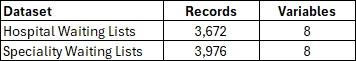


Each dataset contains eight original variables, including the reporting date, hospital or speciality, adult/child classification, four waiting-time categories and the total number of patients waiting.


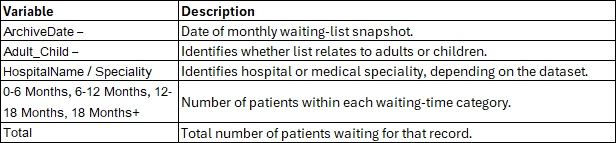


Each record represents a waiting-list count for a particular reporting date, patient group and hospital or speciality. As these are monthly snapshots rather than individual patient records, the same patient may appear in multiple reporting periods.

These datasets were selected because they allow comparisons over time and across different services and patient groups.


In [39]:
# Import libraries needed for analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [40]:
# Upload the datasets
from google.colab import files
uploaded = files.upload()

Saving Speciality_Waiting_Lists_Ireland_2022_to_2025.csv to Speciality_Waiting_Lists_Ireland_2022_to_2025 (2).csv
Saving Hospital_Waiting_Lists_Ireland_2022_to_2025.csv to Hospital_Waiting_Lists_Ireland_2022_to_2025 (2).csv


In [41]:
# Read datasets
hospital_df = pd.read_csv('Hospital_Waiting_Lists_Ireland_2022_to_2025.csv')
speciality_df = pd.read_csv('Speciality_Waiting_Lists_Ireland_2022_to_2025.csv')

### 3.2 Initial Data Exploration

Initial exploration was carried out using Pandas to examine the structure, dimensions, data types and missing values in both datasets.

The Hospital dataset contained 3,672 records and the Speciality dataset contained 3,976 records, each with eight original variables.

No missing values were identified. However, the reporting dates and patient counts were initially imported as object data types, requiring conversion before further analysis.

In [42]:
# Display the head and tail records of each dataset

# Hospital - first 5 and last 5 records
print("Hospital Dataset (first 5 rows):")
display(hospital_df.head())

print("Hospital Dataset (last 5 rows):")
display(hospital_df.tail())

# Speciality - first 5 and last 5 records
print("Speciality Dataset (first 5 rows):")
display(speciality_df.head())

print("Speciality Dataset (last 5 rows):")
display(speciality_df.tail())


# Display number of rows and columns for each dataset
print("The number of rows and columns for each dataset is as follows:")
print("Hospital Dataset:", hospital_df.shape)
print("Speciality Dataset:", speciality_df.shape)


# Display info on each dataset
print("Information for each dataset is as follows:")
print("Hospital Dataset:")
hospital_df.info()
print("Speciality Dataset:")
speciality_df.info()


# Display missing values, if any, for each dataset
print("Missing values, if any, for each dataset are as follows:")
print("Hospital Dataset:", hospital_df.isnull().sum())
print("Speciality Dataset:", speciality_df.isnull().sum())



Hospital Dataset (first 5 rows):


,ArchiveDate,Adult_Child,HospitalName,0-6 Months,6-12 Months,12-18 Months,18 Months +,Total
0,27/01/2022,Adult,Bantry General Hospital,634,309,209,207,"1,359"
1,27/01/2022,Adult,Beaumont Hospital,"18,302","5,357",276,132,"24,066"
2,27/01/2022,Adult,Cavan General Hospital,"3,498","1,724",376,360,"5,958"
3,27/01/2022,Adult,Connolly Hospital Blanchardstown,"4,371",762,54,17,"5,203"
4,27/01/2022,Adult,Coombe Women and Infants University Hospital,"1,583",563,286,353,"2,785"


Hospital Dataset (last 5 rows):


,ArchiveDate,Adult_Child,HospitalName,0-6 Months,6-12 Months,12-18 Months,18 Months +,Total
3667,18/12/2025,Child,Tipperary University Hospital,390,76,35,1,502
3668,18/12/2025,Child,University Hospital Kerry,628,195,113,67,"1,003"
3669,18/12/2025,Child,University Hospital Limerick,"2,579",857,393,280,"4,109"
3670,18/12/2025,Child,University Hospital Waterford,"2,064",975,328,340,"3,707"
3671,18/12/2025,Child,Wexford General Hospital,734,313,0,0,"1,047"


Speciality Dataset (first 5 rows):


,ArchiveDate,Adult_Child,Speciality,0-6 Months,6-12 Months,12-18 Months,18 Months +,Total
0,27/01/2022,Adult,Anaesthetics,54,61,23,172,310
1,27/01/2022,Adult,Breast Surgery,"2,653",652,137,92,"3,534"
2,27/01/2022,Adult,Cardio-Thoracic Surgery,290,42,27,21,380
3,27/01/2022,Adult,Cardiology,"15,981","8,062","4,618","5,386","34,047"
4,27/01/2022,Adult,Chemical Pathology,72,32,12,2,118


Speciality Dataset (last 5 rows):


,ArchiveDate,Adult_Child,Speciality,0-6 Months,6-12 Months,12-18 Months,18 Months +,Total
3971,18/12/2025,Child,Plastic Surgery,877,197,101,77,"1,252"
3972,18/12/2025,Child,Rheumatology,259,161,99,87,606
3973,18/12/2025,Child,Small Volume Specialties,546,88,30,9,673
3974,18/12/2025,Child,Urology,"1,018",588,388,76,"2,070"
3975,18/12/2025,Child,Vascular Surgery,13,4,6,0,23


The number of rows and columns for each dataset is as follows:
Hospital Dataset: (3672, 8)
Speciality Dataset: (3976, 8)
Information for each dataset is as follows:
Hospital Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3672 entries, 0 to 3671
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   ArchiveDate   3672 non-null   object
 1   Adult_Child   3672 non-null   object
 2   HospitalName  3672 non-null   object
 3   0-6 Months    3672 non-null   object
 4   6-12 Months   3672 non-null   object
 5   12-18 Months  3672 non-null   object
 6   18 Months +   3672 non-null   object
 7   Total         3672 non-null   object
dtypes: object(8)
memory usage: 229.6+ KB
Speciality Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3976 entries, 0 to 3975
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   ArchiveDate   3976 non-null   obje

### 3.3 Data Cleaning

The `ArchiveDate` column was converted into a datetime data type using the day/month/year format. Patient counts were converted to integers after removing thousands separators.

Both datasets were checked for repeated combinations of reporting date, patient group and hospital or speciality.

No repeated combinations were identified in the Hospital dataset. The Speciality dataset contained 57 repeated combinations, which were retained because they were not confirmed to be identical duplicate records.

These records were noted as a data-quality limitation rather than removed automatically. The main speciality comparisons use the first and last reporting periods, which were not affected by these repeated combinations.

In [43]:
# Convert ArchiveDate to datetime data type in both datasets
hospital_df['ArchiveDate'] = pd.to_datetime(hospital_df['ArchiveDate'], format='%d/%m/%Y')
speciality_df['ArchiveDate'] = pd.to_datetime(speciality_df['ArchiveDate'], format='%d/%m/%Y')


# Convert patient count (number) columns to integers
# Identify patient count columns
patient_count_col=['0-6 Months', '6-12 Months', '12-18 Months', '18 Months +', 'Total']
# Convert patient count columns to integer data type in both datasets
for col in patient_count_col:
  hospital_df[col] = hospital_df[col].str.replace(",","").astype(int)
  speciality_df[col] = speciality_df[col].str.replace(",","").astype(int)

# Display info on each dataset
print("Information for each dataset is as follows:")
print("Hospital Dataset:")
hospital_df.info()
print("Speciality Dataset:")
speciality_df.info()

Information for each dataset is as follows:
Hospital Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3672 entries, 0 to 3671
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   ArchiveDate   3672 non-null   datetime64[ns]
 1   Adult_Child   3672 non-null   object        
 2   HospitalName  3672 non-null   object        
 3   0-6 Months    3672 non-null   int64         
 4   6-12 Months   3672 non-null   int64         
 5   12-18 Months  3672 non-null   int64         
 6   18 Months +   3672 non-null   int64         
 7   Total         3672 non-null   int64         
dtypes: datetime64[ns](1), int64(5), object(2)
memory usage: 229.6+ KB
Speciality Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3976 entries, 0 to 3975
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   ArchiveDate   3976 non-null   

In [44]:
# Check for duplicate records - date and object data type columns in both datasets
hospital_duplicates = hospital_df.duplicated(subset=['ArchiveDate', 'Adult_Child', 'HospitalName'])
speciality_duplicates = speciality_df.duplicated(subset=['ArchiveDate', 'Adult_Child', 'Speciality'])

print("Hospital repeated combinations:", hospital_duplicates.sum())
print("Speciality repeated combinations:", speciality_duplicates.sum())

Hospital repeated combinations: 0
Speciality repeated combinations: 57


### 3.4 Data Transformation

Year and month variables were extracted from the reporting dates to support chronological analysis.

A new variable, `12+ Months`, was created by combining patients waiting 12–18 months and over 18 months.

The percentage waiting 12 months or longer was then calculated as:

**12+ Percent = (12+ Months / Total) × 100**

This measure was selected to allow comparisons between hospitals and specialities with different waiting-list sizes.

When calculating national or grouped percentages, patient counts were aggregated before calculating the percentage to avoid giving small and large waiting lists equal weighting.

In [45]:
# Extract the year and month from ArchiveDate in both datasets
hospital_df['Year'] = hospital_df['ArchiveDate'].dt.year
hospital_df['Month'] = hospital_df['ArchiveDate'].dt.month

speciality_df['Year'] = speciality_df['ArchiveDate'].dt.year
speciality_df['Month'] = speciality_df['ArchiveDate'].dt.month

# Display the new columns
print("Hospital Dataset:")
display(hospital_df[['ArchiveDate', 'Year', 'Month']].head())

print("Speciality Dataset:")
display(speciality_df[['ArchiveDate', 'Year', 'Month']].head())


# Calculate the number of patients waiting 12+ months
hospital_df['12+ Months'] = hospital_df['12-18 Months'] + hospital_df['18 Months +']

speciality_df['12+ Months'] = speciality_df['12-18 Months'] + speciality_df['18 Months +']

# Display the results
print("Hospital Dataset:")
display(hospital_df[['12-18 Months', '18 Months +', '12+ Months']].head())

print("Speciality Dataset:")
display(speciality_df[['12-18 Months', '18 Months +', '12+ Months']].head())


# Calculate the percentage of patients waiting 12+ months
hospital_df['12+ Percent'] = np.where(
    hospital_df['Total'] > 0,
    hospital_df['12+ Months'] / hospital_df['Total'] * 100,
    np.nan
)

speciality_df['12+ Percent'] = np.where(
    speciality_df['Total'] > 0,
    speciality_df['12+ Months'] / speciality_df['Total'] * 100,
    np.nan
)

# Display the calculated percentages
print("Hospital Dataset:")
display(hospital_df[['Total', '12+ Months', '12+ Percent']].head())

print("Speciality Dataset:")
display(speciality_df[['Total', '12+ Months', '12+ Percent']].head())

Hospital Dataset:


,ArchiveDate,Year,Month
0,2022-01-27,2022,1
1,2022-01-27,2022,1
2,2022-01-27,2022,1
3,2022-01-27,2022,1
4,2022-01-27,2022,1


Speciality Dataset:


,ArchiveDate,Year,Month
0,2022-01-27,2022,1
1,2022-01-27,2022,1
2,2022-01-27,2022,1
3,2022-01-27,2022,1
4,2022-01-27,2022,1


Hospital Dataset:


,12-18 Months,18 Months +,12+ Months
0,209,207,416
1,276,132,408
2,376,360,736
3,54,17,71
4,286,353,639


... (2 outputs left out)

Hospital Dataset:


,Total,12+ Months,12+ Percent
0,1359,416,30.610743
1,24066,408,1.695338
2,5958,736,12.353139
3,5203,71,1.364597
4,2785,639,22.944345


Speciality Dataset:


,Total,12+ Months,12+ Percent
0,310,195,62.903226
1,3534,229,6.479909
2,380,48,12.631579
3,34047,10004,29.382912
4,118,14,11.864407


### 3.5 Analytical and Visualisation Approach

The analysis followed a descriptive and exploratory approach using Python, Pandas, NumPy and Matplotlib in Google Colab.

Descriptive statistics were used to examine differences in waiting-list sizes, while monthly trends were visualised using line graphs.

Grouped bar charts were used to compare waiting-time categories, hospitals, medical specialities and adult and child waiting lists. Percentage-point changes and patient counts were considered together to avoid misleading comparisons between differently sized waiting lists.

A static dashboard was also created to summarise the principal findings.

The analysis focuses on identifying and interpreting trends rather than establishing causal relationships.

### 3.6 Supplementary Data and Analysis Methods

In addition to the NTPF waiting-list datasets, supplementary data from the HSE, Central Statistics Office (CSO) and Department of Health was used to investigate factors potentially influencing outpatient waiting-list trends.

Annual outpatient waiting-list additions and removals were obtained from the HSE Waiting List Action Plan End of Year Reports. These figures were entered into a Pandas DataFrame, and the annual net change was calculated by subtracting removals from additions.

Population estimates from the CSO were used to calculate outpatient waiting-list entries per 100,000 residents. December waiting-list totals were compared with April population estimates for each year.

Annual outpatient attendance figures and consultant whole-time equivalent (WTE) staffing figures were also examined. Percentage changes were calculated, and both measures were indexed to a common baseline of 100 in 2022 to compare their relative growth.

The supplementary analysis was descriptive and exploratory. Its purpose was to identify patterns and possible contributing factors rather than establish causal relationships. The HSE additions and removals figures were rounded, outpatient attendances included new and return appointments, and consultant staffing figures covered the wider public hospital service.

## 4. RESULTS AND ANALYSIS

### 4.1 Descriptive Statistics

Descriptive statistics were calculated to examine the distribution of waiting-list sizes and longer waiting times across hospitals and medical specialities.

Mean, median, standard deviation and range were used to identify variation in the datasets before examining trends over time.

In [46]:
# Display descriptive statistics for patient count columns
print("Hospital Dataset:")
display(hospital_df[patient_count_col].describe().round(2))

print("\nSpeciality Dataset:")
display(speciality_df[patient_count_col].describe().round(2))


Hospital Dataset:


,0-6 Months,6-12 Months,12-18 Months,18 Months +,Total
count,3672.00,3672.00,3672.00,3672.00,3672.00
mean,4335.65,1748.32,767.70,989.90,7841.51
std,6010.63,2599.78,1292.27,2207.11,11330.81
min,1.00,0.00,0.00,0.00,1.00
25%,470.00,155.00,20.00,2.00,793.50
50%,2103.50,698.50,218.50,107.00,3445.50
75%,4630.00,1935.50,773.50,733.00,8819.00
max,28561.00,14487.00,7168.00,16909.00,51411.00



Speciality Dataset:


,0-6 Months,6-12 Months,12-18 Months,18 Months +,Total
count,3976.00,3976.00,3976.00,3976.00,3976.00
mean,4004.20,1614.60,709.00,914.16,7241.95
std,7073.66,2959.17,1301.98,1922.57,12517.78
min,0.00,0.00,0.00,0.00,2.00
25%,110.00,35.75,10.00,2.00,218.75
50%,785.50,291.00,124.00,97.00,1462.00
75%,3766.75,1838.00,815.00,772.00,8098.75
max,41293.00,19024.00,10591.00,20712.00,70471.00


In [47]:

# Descriptive statistics for patients waiting 12 months or longer
print("Hospital Dataset - 12+ Months:")
display(hospital_df[['12+ Months', '12+ Percent']].describe().round(2))

print("\nSpeciality Dataset - 12+ Months:")
display(speciality_df[['12+ Months', '12+ Percent']].describe().round(2))


Hospital Dataset - 12+ Months:


,12+ Months,12+ Percent
count,3672.00,3672.00
mean,1757.60,15.75
std,3387.83,13.63
min,0.00,0.00
25%,29.00,4.30
50%,378.00,12.97
75%,1539.50,23.80
max,23739.00,90.62



Speciality Dataset - 12+ Months:


,12+ Months,12+ Percent
count,3976.00,3976.00
mean,1623.16,20.05
std,3087.11,16.01
min,0.00,0.00
25%,17.00,7.06
50%,231.00,17.39
75%,1588.50,29.50
max,26483.00,96.88


The descriptive statistics indicate considerable variation in outpatient waiting-list sizes across hospitals and specialities.

In both datasets, the mean patient count was substantially higher than the median, indicating positively skewed distributions where larger waiting lists influence the average.

The median proportion waiting 12 months or longer was 12.97% in the Hospital dataset and 17.39% in the Speciality dataset. However, these statistics represent individual monthly records rather than national waiting-time rates.

These findings highlight the importance of considering differences in waiting-list sizes when comparing hospitals and specialities. The following analysis examines how waiting-list numbers and waiting times changed between 2022 and 2025.

### 4.2 National Waiting-List Trends

Monthly outpatient waiting-list totals were analysed to examine changes in the number of patients awaiting appointments between January 2022 and December 2025.

The proportion waiting 12 months or longer was also calculated to determine whether changes in longer waiting times reflected changes in the overall waiting-list size.

In [48]:

# Calculate monthly national outpatient waiting-list totals
monthly_hospital = hospital_df.groupby('ArchiveDate', as_index=False)[
    ['Total', '12+ Months']
].sum()

# Sort the results by reporting date
monthly_hospital = monthly_hospital.sort_values('ArchiveDate')

# Calculate the national percentage waiting 12 months or longer
monthly_hospital['12+ Percent'] = (
    monthly_hospital['12+ Months'] / monthly_hospital['Total'] * 100
)

# Display the first and last five reporting periods
print("First five reporting periods:")
display(monthly_hospital.head().round(2))

print("Last five reporting periods:")
display(monthly_hospital.tail().round(2))


First five reporting periods:


,ArchiveDate,Total,12+ Months,12+ Percent
0,2022-01-27,625519,227672,36.40
1,2022-02-24,626661,220751,35.23
2,2022-03-31,625054,216346,34.61
3,2022-04-28,624773,212146,33.96
4,2022-05-26,624447,204094,32.68


Last five reporting periods:


,ArchiveDate,Total,12+ Months,12+ Percent
43,2025-08-28,623008,105715,16.97
44,2025-09-25,626521,107116,17.10
45,2025-10-30,626960,108180,17.25
46,2025-11-27,623819,104825,16.80
47,2025-12-18,611987,100230,16.38


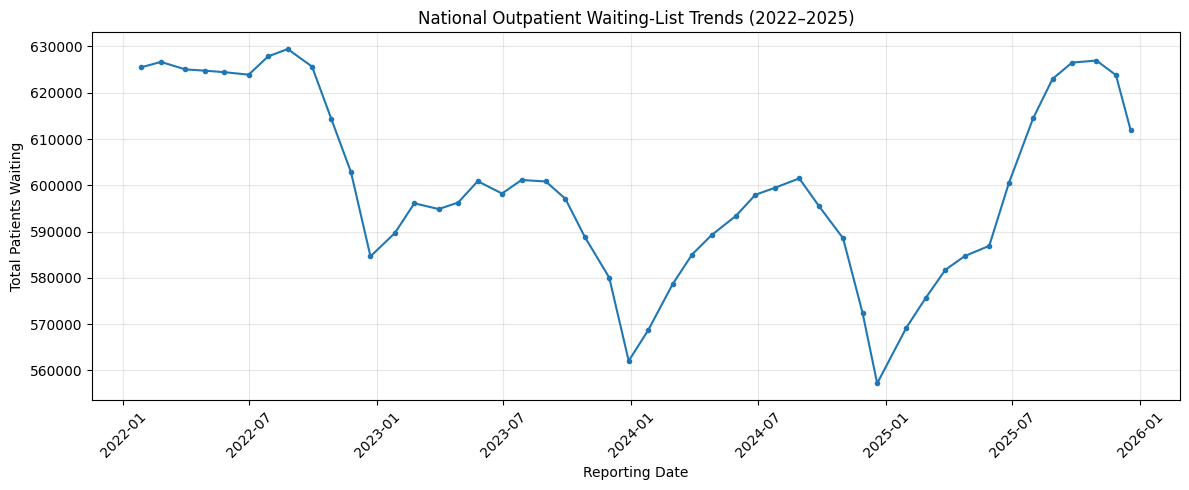

In [49]:

# Plot national outpatient waiting-list totals from 2022 to 2025
plt.figure(figsize=(12, 5))

plt.plot(monthly_hospital['ArchiveDate'],
         monthly_hospital['Total'],
         marker='o',
         markersize=3)

plt.title('National Outpatient Waiting-List Trends (2022–2025)')
plt.xlabel('Reporting Date')
plt.ylabel('Total Patients Waiting')

plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


The total outpatient waiting list decreased from 625,519 patients in January 2022 to 611,987 in December 2025, representing a reduction of 2.16%.

However, the monthly trend was not consistent. Waiting-list numbers declined during 2022 and 2023, reached lower levels towards the end of 2024, and increased again during much of 2025.

This indicates that overall waiting-list numbers remained under pressure despite the reduction across the study period. However, the total number waiting does not indicate how long patients have been waiting for an appointment.

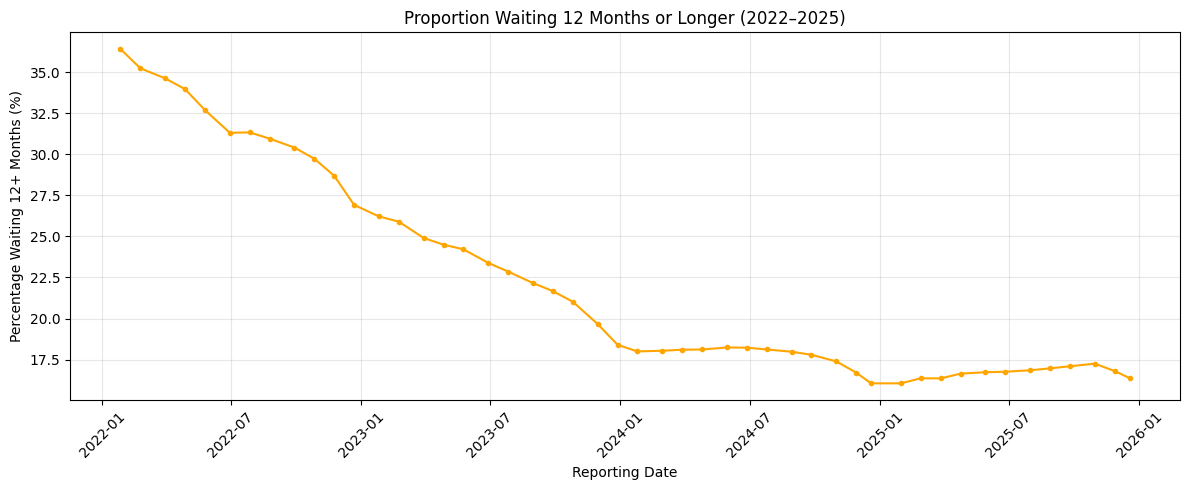

In [50]:

# Plot the percentage of patients waiting 12 months or longer
plt.figure(figsize=(12, 5))

plt.plot(monthly_hospital['ArchiveDate'],
         monthly_hospital['12+ Percent'],
         marker='o',
         markersize=3,
         color='orange')


plt.title('Proportion Waiting 12 Months or Longer (2022–2025)')
plt.xlabel('Reporting Date')
plt.ylabel('Percentage Waiting 12+ Months (%)')

plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


The proportion of patients waiting 12 months or longer decreased from 36.40% in January 2022 to 16.38% in December 2025, a reduction of 20.02 percentage points.

In absolute terms, the number waiting 12 months or longer fell from 227,672 to 100,230 patients, representing a reduction of 55.98%.

The largest improvements occurred during 2022 and 2023, followed by a slower rate of change during 2024 and 2025.

This reveals a substantially different picture from the overall waiting-list trend. Although the total number of patients waiting decreased by only 2.16%, the number experiencing longer waits fell considerably.

The results demonstrate why both waiting-list size and waiting-time distribution are necessary when assessing outpatient waiting-list performance.

### 4.3 Waiting-Time Distribution

To investigate why the overall outpatient waiting-list total changed relatively little despite a substantial reduction in longer waits, patients were grouped into two categories: those waiting less than 12 months and those waiting 12 months or longer.

Patient numbers and their proportions of the total waiting list were compared between January 2022 and December 2025 to examine how the waiting-time distribution changed over the study period.

In [55]:
# Compare waiting-time categories at the beginning and end of the study period

# Define the original four waiting-time categories
waiting_bands = [
    '0-6 Months',
    '6-12 Months',
    '12-18 Months',
    '18 Months +'
]

# Identify the first and last reporting dates
comparison_dates = [
    hospital_df['ArchiveDate'].min(),
    hospital_df['ArchiveDate'].max()
]

# Calculate national patient counts for each waiting-time category
waiting_comparison = (
    hospital_df[hospital_df['ArchiveDate'].isin(comparison_dates)]
    .groupby('ArchiveDate')[waiting_bands]
    .sum()
    .sort_index()
)

# Calculate percentages for the four-category dashboard chart
waiting_percent = waiting_comparison.div(
    waiting_comparison.sum(axis=1), axis=0
) * 100

# Format reporting dates for the dashboard
waiting_percent.index = waiting_percent.index.strftime('%b %Y')

# Create a three-category comparison for the main graph
waiting_comparison_3cat = waiting_comparison.copy()

# Combine 12-18 months and 18 months+ into one category
waiting_comparison_3cat['12+ Months'] = (
    waiting_comparison_3cat['12-18 Months'] +
    waiting_comparison_3cat['18 Months +']
)

# Retain the three categories required
waiting_comparison_3cat = waiting_comparison_3cat[
    ['0-6 Months', '6-12 Months', '12+ Months']
]

# Format dates for display
waiting_comparison_3cat.index = (
    waiting_comparison_3cat.index.strftime('%b %Y')
)

# Display the comparison tables
print('Waiting-time distribution (%):')
display(waiting_percent.round(2))

print('Patient counts by waiting-time category:')
display(waiting_comparison_3cat)


Waiting-time distribution (%):


,0-6 Months,6-12 Months,12-18 Months,18 Months +
ArchiveDate,,,,
Jan 2022,43.07,20.53,11.54,24.86
Dec 2025,60.66,22.96,9.16,7.21


Patient counts by waiting-time category:


,0-6 Months,6-12 Months,12+ Months
ArchiveDate,,,
Jan 2022,269419,128439,227672
Dec 2025,371237,140532,100230


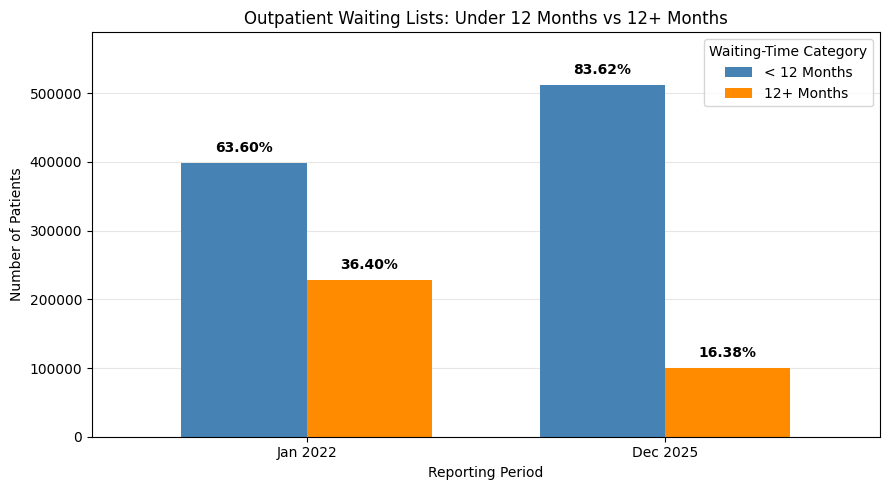

In [60]:
# Create a two-category comparison: under 12 months vs 12+ months

waiting_comparison_2cat = pd.DataFrame(index=waiting_comparison_3cat.index)

waiting_comparison_2cat['< 12 Months'] = (
    waiting_comparison_3cat['0-6 Months'] +
    waiting_comparison_3cat['6-12 Months']
)

waiting_comparison_2cat['12+ Months'] = (
    waiting_comparison_3cat['12+ Months']
)

# Calculate percentages within each reporting period
waiting_comparison_2cat_percent = waiting_comparison_2cat.div(
    waiting_comparison_2cat.sum(axis=1),
    axis=0
) * 100

# Plot grouped bar chart
ax = waiting_comparison_2cat.plot(
    kind='bar',
    figsize=(9, 5),
    width=0.7,
    color=['steelblue', 'darkorange']
)

# Add percentage labels above each bar
for i, category in enumerate(waiting_comparison_2cat.columns):
    for j, bar in enumerate(ax.containers[i]):
        percentage = waiting_comparison_2cat_percent.iloc[j, i]
        ax.annotate(
            f'{percentage:.2f}%',
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 6),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=10,
            fontweight='bold'
        )

plt.title('Outpatient Waiting Lists: Under 12 Months vs 12+ Months')
plt.xlabel('Reporting Period')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.legend(title='Waiting-Time Category')
plt.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

ax.set_ylim(0, waiting_comparison_2cat.to_numpy().max() * 1.15)

plt.tight_layout()
plt.show()



**Findings**

Between January 2022 and December 2025, the proportion of patients waiting less than 12 months increased from 63.60% to 83.62%, while the proportion waiting 12 months or longer decreased from 36.40% to 16.38%.

In absolute terms, approximately 114,000 more patients were waiting less than 12 months, while the number waiting 12 months or longer decreased by 127,442 (55.98%).

These changes largely offset one another, helping to explain why the overall waiting-list total decreased by only 2.16%.

This demonstrates that overall waiting-list numbers alone do not fully reflect changes in waiting times. However, the data cannot establish what caused the reduction in longer waits.

### 4.4 Adult and Child Waiting-List Comparisons

Adult and child outpatient waiting lists were compared to determine whether the national reduction in longer waits was evident across both patient groups.

The analysis considers the proportion waiting 12 months or longer, allowing comparisons between groups with substantially different waiting-list sizes.

In [61]:

# Compare adult and child waiting lists at the beginning and end

adult_child_comparison = (
    hospital_df[hospital_df['ArchiveDate'].isin(comparison_dates)]
    .groupby(['ArchiveDate', 'Adult_Child'])[
        ['Total', '12+ Months']
    ]
    .sum()
    .reset_index()
)

# Calculate the percentage waiting 12 months or longer
adult_child_comparison['12+ Percent'] = (
    adult_child_comparison['12+ Months'] /
    adult_child_comparison['Total'] * 100
)

# Format reporting dates
adult_child_comparison['ArchiveDate'] = (
    adult_child_comparison['ArchiveDate'].dt.strftime('%b %Y')
)

display(adult_child_comparison.round(2))


,ArchiveDate,Adult_Child,Total,12+ Months,12+ Percent
0,Jan 2022,Adult,540602,194400,35.96
1,Jan 2022,Child,84917,33272,39.18
2,Dec 2025,Adult,542556,88233,16.26
3,Dec 2025,Child,69431,11997,17.28


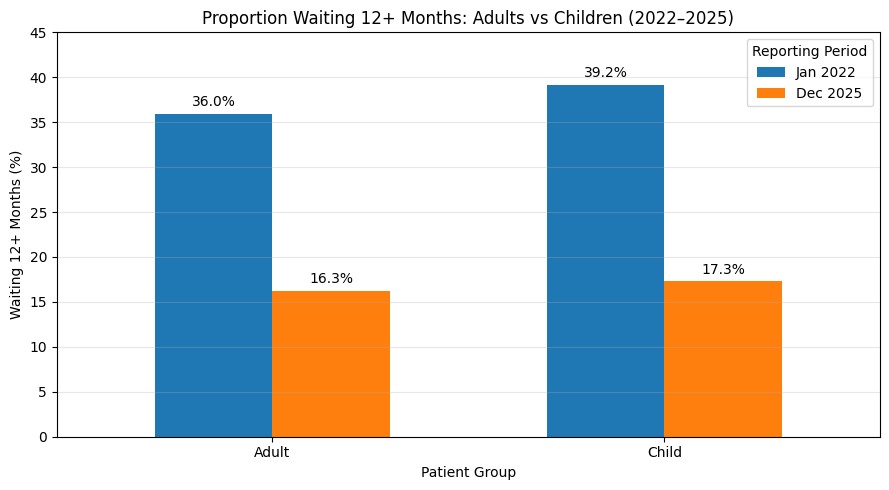

In [63]:

# Compare the percentage waiting 12+ months for adults and children

adult_child_percent = adult_child_comparison.pivot(
    index='Adult_Child',
    columns='ArchiveDate',
    values='12+ Percent'
)

# Plot grouped bar chart
ax = adult_child_percent[['Jan 2022', 'Dec 2025']].plot(
    kind='bar',
    figsize=(9, 5),
    width=0.6
)

plt.title('Proportion Waiting 12+ Months: Adults vs Children (2022–2025)')
plt.xlabel('Patient Group')
plt.ylabel('Waiting 12+ Months (%)')
plt.xticks(rotation=0)
plt.ylim(0, 45)
plt.legend(title='Reporting Period')

# Display percentage labels above bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**Findings**

The proportion of patients waiting 12 months or longer decreased substantially for both adults (35.96% to 16.26%) and children (39.18% to 17.28%) between January 2022 and December 2025.

However, the overall waiting-list totals followed different patterns. Adult waiting-list numbers remained relatively stable (+0.36%), while children's waiting lists decreased by 18.24%.

Children had a higher proportion of longer waits in both periods, although the gap between the groups narrowed from 3.22 to 1.02 percentage points.

These findings demonstrate that improvements in the waiting-time profile were evident across both patient groups, despite differences in their overall waiting-list trends. The data does not establish why these changes differed.

### 4.5 Hospital Comparisons

Hospital waiting lists were compared to identify where the largest reductions in long-waiting patient numbers occurred and whether improvements were consistent across hospitals.

Changes in both patient counts and the proportion waiting 12 months or longer were examined between January 2022 and December 2025. Absolute counts help identify hospitals recording the largest reductions, while percentages account for differences in waiting-list size.

In [71]:

# Compare hospital waiting lists in January 2022 and December 2025

hospital_comparison = (
    hospital_df[hospital_df['ArchiveDate'].isin(comparison_dates)]
    .groupby(['HospitalName', 'ArchiveDate'], as_index=False)[
        ['Total', '12+ Months']
    ]
    .sum()
)

# Calculate the percentage waiting 12 months or longer
hospital_comparison['12+ Percent'] = (
    hospital_comparison['12+ Months'] /
    hospital_comparison['Total'] * 100
)

# Check the number of hospitals in each reporting period
hospital_counts = hospital_comparison.groupby(
    'ArchiveDate'
)['HospitalName'].nunique()

print("Hospitals represented in each reporting period:")
for date, count in hospital_counts.items():
    print(f"{date:%b %Y}: {count}")


Hospitals represented in each reporting period:
Jan 2022: 44
Dec 2025: 44


In [72]:

# Compare hospitals represented in both reporting periods

hospital_pivot = hospital_comparison.pivot(
    index='HospitalName',
    columns='ArchiveDate',
    values='12+ Percent'
)

# Keep only hospitals represented in both periods
hospital_changes = hospital_pivot.dropna().copy()

# Calculate the change in percentage points
hospital_changes['Change (pp)'] = (
    hospital_changes[comparison_dates[1]] -
    hospital_changes[comparison_dates[0]]
)

# Rename the reporting dates for easier reading
hospital_changes = hospital_changes.rename(columns={
    comparison_dates[0]: 'Jan 2022',
    comparison_dates[1]: 'Dec 2025'
})

# Count reductions and increases
hospitals_decreased = (
    hospital_changes['Change (pp)'] < 0
).sum()

hospitals_increased = (
    hospital_changes['Change (pp)'] > 0
).sum()

hospitals_unchanged = (
    hospital_changes['Change (pp)'] == 0
).sum()

# Display summary
print("Hospital comparison summary")
print("---------------------------")
print(f"Hospitals compared: {len(hospital_changes)}")
print(f"Hospitals with a decrease: {hospitals_decreased}")
print(f"Hospitals with an increase: {hospitals_increased}")
print(f"Hospitals with no change: {hospitals_unchanged}")

print(
    f"\nPercentage with a decrease: "
    f"{hospitals_decreased / len(hospital_changes) * 100:.2f}%"
)

# Check how many hospital labels could not be matched
unmatched = hospital_pivot.isna().any(axis=1).sum()

print(f"Hospital labels not matched: {unmatched}")


Hospital comparison summary
---------------------------
Hospitals compared: 43
Hospitals with a decrease: 34
Hospitals with an increase: 9
Hospitals with no change: 0

Percentage with a decrease: 79.07%
Hospital labels not matched: 2


In [92]:

# Compare total waiting-list sizes for matched hospitals

hospital_totals = hospital_comparison.pivot(
    index='HospitalName',
    columns='ArchiveDate',
    values='Total'
)

# Rename reporting periods
hospital_totals = hospital_totals.rename(columns={
    comparison_dates[0]: 'Total Jan 2022',
    comparison_dates[1]: 'Total Dec 2025'
})

# Combine percentages with patient counts
hospital_detail = hospital_changes.join(hospital_totals)

# Compare the number of patients waiting 12+ months by hospital

long_wait_pivot = hospital_comparison.pivot(
    index='HospitalName',
    columns='ArchiveDate',
    values='12+ Months'
)

# Add patient counts to the existing hospital comparison
hospital_detail['12+ Jan 2022'] = long_wait_pivot.loc[
    hospital_detail.index, comparison_dates[0]
]

hospital_detail['12+ Dec 2025'] = long_wait_pivot.loc[
    hospital_detail.index, comparison_dates[1]
]

# Calculate the change in actual patient numbers
hospital_detail['Change in 12+ Patients'] = (
    hospital_detail['12+ Dec 2025'] -
    hospital_detail['12+ Jan 2022']
)

# Select key measures for a clearer comparison
hospital_display_cols = [
    '12+ Jan 2022',
    '12+ Dec 2025',
    'Change in 12+ Patients',
    'Change (pp)'
]

# Format patient counts as whole numbers for display
hospital_display = hospital_detail[hospital_display_cols].copy()

count_cols = [
    '12+ Jan 2022',
    '12+ Dec 2025',
    'Change in 12+ Patients'
]

hospital_display[count_cols] = hospital_display[count_cols].astype(int)


# Improve table headings
hospital_detail.columns.name = None
hospital_detail.index.name = 'Hospital'

# Remove the old column heading and rename the index
hospital_display.columns.name = None
hospital_display.index.name = 'Hospital'

# Display the five largest reductions
print("Five largest reductions in long-waiting patients:")

display(
    hospital_display.nsmallest(
        5, 'Change in 12+ Patients'
    ).round(2)
)

# Display the two largest increases
print("\nTwo largest increases in long-waiting patients:")

display(
    hospital_display.nlargest(
        2, 'Change in 12+ Patients'
    ).round(2)
)




# Compare matched hospital changes with the national change
national_change = int(
    monthly_hospital.iloc[-1]['12+ Months'] -
    monthly_hospital.iloc[0]['12+ Months']
)

matched_change = int(hospital_detail['Change in 12+ Patients'].sum())

print(f"\nNational change in 12+ patients: {national_change:+,}")
print(f"Change across 43 matched hospitals: {matched_change:+,}")


Five largest reductions in long-waiting patients:


,12+ Jan 2022,12+ Dec 2025,Change in 12+ Patients,Change (pp)
Hospital,,,,
University Hospital Limerick,23789,3449,-20340,-40.50
Galway University Hospitals,25678,10329,-15349,-23.81
Cork University Hospital,15382,1582,-13800,-34.00
Children's Health Ireland,18713,6009,-12704,-23.26
Tallaght University Hospital,15130,3266,-11864,-28.00



Two largest increases in long-waiting patients:


,12+ Jan 2022,12+ Dec 2025,Change in 12+ Patients,Change (pp)
Hospital,,,,
Beaumont Hospital,410,5593,5183,10.34
St. Columcille's Hospital,2755,6536,3781,19.94



National change in 12+ patients: -127,442
Change across 43 matched hospitals: -127,557


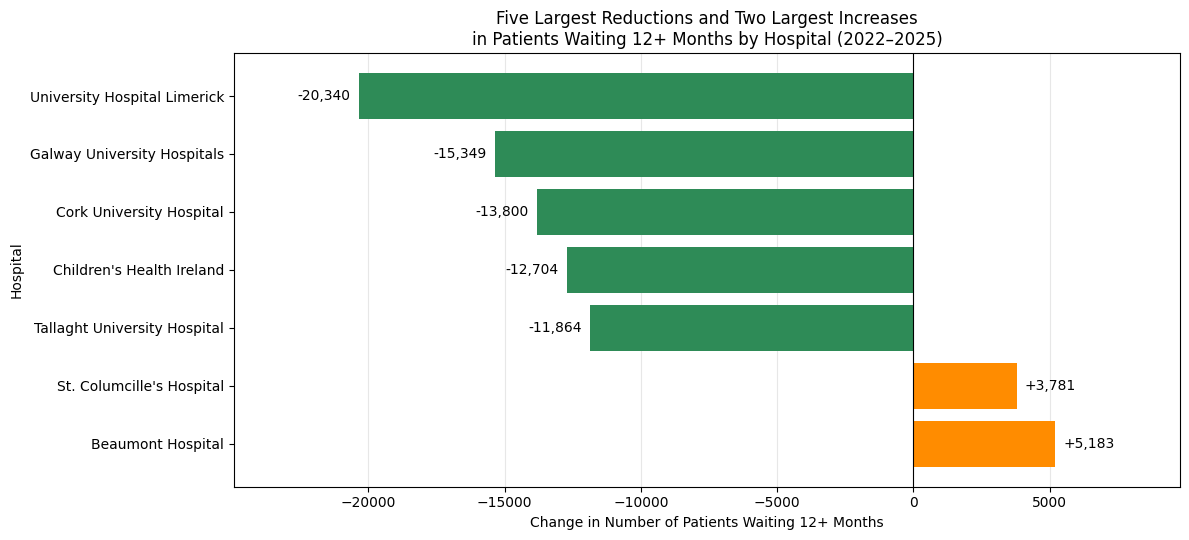

In [93]:

# Select five largest decreases and two largest increases

top_hospitals = pd.concat([
    hospital_detail.nsmallest(5, 'Change in 12+ Patients'),
    hospital_detail.nlargest(2, 'Change in 12+ Patients')
]).sort_values('Change in 12+ Patients')

# Assign colours
colours = [
    'seagreen' if value < 0 else 'darkorange'
    for value in top_hospitals['Change in 12+ Patients']
]

# Create chart
fig, ax = plt.subplots(figsize=(12, 5.5))

bars = ax.barh(
    top_hospitals.index,
    top_hospitals['Change in 12+ Patients'],
    color=colours
)

# Add value labels
for bar, value in zip(
    bars, top_hospitals['Change in 12+ Patients']
):
    ax.annotate(
        f'{value:+,.0f}',
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(6 if value >= 0 else -6, 0),
        textcoords='offset points',
        va='center',
        ha='left' if value >= 0 else 'right'
    )

ax.axvline(0, color='black', linewidth=0.8)
ax.invert_yaxis()
ax.margins(x=0.18)

plt.title(
    'Five Largest Reductions and Two Largest Increases\n'
    'in Patients Waiting 12+ Months by Hospital (2022–2025)'
)

plt.xlabel('Change in Number of Patients Waiting 12+ Months')
plt.ylabel('Hospital')

plt.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Findings**

Of the 43 hospitals represented in both reporting periods, 34 (79%) recorded a reduction in the proportion of patients waiting 12 months or longer.

In absolute terms, University Hospital Limerick recorded the largest reduction (20,340 patients), followed by Galway University Hospitals (15,349) and Cork University Hospital (13,800). The five hospitals with the largest reductions recorded a combined decrease of 74,057 long-waiting patients, equivalent to approximately 58% of the national net reduction.

However, improvements were not universal. Beaumont Hospital recorded an increase of 5,183 long-waiting patients, followed by St. Columcille's Hospital (3,781).

These findings identify where some of the largest changes occurred and demonstrate that the national reduction was unevenly distributed across hospitals. However, the waiting-list data alone cannot establish the reasons for these differences.

### 4.6 Speciality Comparisons

Medical specialities were compared to identify which services recorded the largest reductions in patients waiting 12 months or longer.

Changes in both patient numbers and percentages were examined between January 2022 and December 2025. This allows the analysis to identify specialities contributing to the overall reduction while highlighting areas where long-waiting patient numbers continued to increase.

In [87]:

# Compare speciality waiting lists in January 2022 and December 2025

speciality_comparison = (
    speciality_df[speciality_df['ArchiveDate'].isin(comparison_dates)]
    .groupby(['Speciality', 'ArchiveDate'], as_index=False)[
        ['Total', '12+ Months']
    ]
    .sum()
)

# Calculate the percentage waiting 12 months or longer
speciality_comparison['12+ Percent'] = (
    speciality_comparison['12+ Months'] /
    speciality_comparison['Total'] * 100
)

# Check the number of specialities in each reporting period
speciality_counts = speciality_comparison.groupby(
    'ArchiveDate'
)['Speciality'].nunique()

print("Specialities represented in each reporting period:")

for date, count in speciality_counts.items():
    print(f"{date:%b %Y}: {count}")


Specialities represented in each reporting period:
Jan 2022: 62
Dec 2025: 57


In [88]:

# Compare specialities represented in both periods

speciality_pivot = speciality_comparison.pivot(
    index='Speciality',
    columns='ArchiveDate',
    values='12+ Percent'
)

# Keep specialities represented in both periods
speciality_changes = speciality_pivot.dropna().copy()

# Calculate changes in percentage points
speciality_changes['Change (pp)'] = (
    speciality_changes[comparison_dates[1]] -
    speciality_changes[comparison_dates[0]]
)

# Rename reporting periods
speciality_changes = speciality_changes.rename(columns={
    comparison_dates[0]: 'Jan 2022',
    comparison_dates[1]: 'Dec 2025'
})

# Count decreases and increases
specialities_decreased = (
    speciality_changes['Change (pp)'] < 0
).sum()

specialities_increased = (
    speciality_changes['Change (pp)'] > 0
).sum()

specialities_unchanged = (
    speciality_changes['Change (pp)'] == 0
).sum()

# Display summary
print("Speciality comparison summary")
print("----------------------------")
print(f"Specialities compared: {len(speciality_changes)}")
print(f"Specialities with a decrease: {specialities_decreased}")
print(f"Specialities with an increase: {specialities_increased}")
print(f"Specialities with no change: {specialities_unchanged}")

print(
    f"\nPercentage with a decrease: "
    f"{specialities_decreased / len(speciality_changes) * 100:.2f}%"
)

# Identify how many speciality labels could not be matched
unmatched_specialities = speciality_pivot.isna().any(axis=1).sum()

print(f"Speciality labels not matched: {unmatched_specialities}")


Speciality comparison summary
----------------------------
Specialities compared: 55
Specialities with a decrease: 46
Specialities with an increase: 8
Specialities with no change: 1

Percentage with a decrease: 83.64%
Speciality labels not matched: 9


In [94]:

# Compare total waiting-list sizes by speciality

speciality_totals = speciality_comparison.pivot(
    index='Speciality',
    columns='ArchiveDate',
    values='Total'
)

speciality_totals = speciality_totals.rename(columns={
    comparison_dates[0]: 'Total Jan 2022',
    comparison_dates[1]: 'Total Dec 2025'
})

# Compare the number waiting 12+ months
speciality_long_waits = speciality_comparison.pivot(
    index='Speciality',
    columns='ArchiveDate',
    values='12+ Months'
)

speciality_long_waits = speciality_long_waits.rename(columns={
    comparison_dates[0]: '12+ Jan 2022',
    comparison_dates[1]: '12+ Dec 2025'
})

# Combine percentage changes and patient counts
speciality_detail = (
    speciality_changes
    .join(speciality_totals)
    .join(speciality_long_waits)
)

# Calculate absolute change in long-waiting patients
speciality_detail['Change in 12+ Patients'] = (
    speciality_detail['12+ Dec 2025'] -
    speciality_detail['12+ Jan 2022']
)

# Select relevant columns for display
speciality_display_cols = [
    '12+ Jan 2022',
    '12+ Dec 2025',
    'Change in 12+ Patients',
    'Change (pp)'
]

speciality_display = speciality_detail[
    speciality_display_cols
].copy()

# Format patient counts as whole numbers
count_cols = [
    '12+ Jan 2022',
    '12+ Dec 2025',
    'Change in 12+ Patients'
]

speciality_display[count_cols] = (
    speciality_display[count_cols].astype(int)
)

# Tidy table headings
speciality_display.columns.name = None
speciality_display.index.name = 'Speciality'

# Display the five largest reductions
print("Five largest reductions in long-waiting patients:")

display(
    speciality_display.nsmallest(
        5, 'Change in 12+ Patients'
    ).round(2)
)

# Display the two largest increases
print("\nTwo largest increases in long-waiting patients:")

display(
    speciality_display.nlargest(
        2, 'Change in 12+ Patients'
    ).round(2)
)


# Compare changes across matched specialities with the national total

matched_speciality_change = int(
    speciality_detail['Change in 12+ Patients'].sum()
)

national_change = int(
    monthly_hospital.iloc[-1]['12+ Months'] -
    monthly_hospital.iloc[0]['12+ Months']
)

print(f"National change in 12+ patients: {national_change:+,}")
print(
    f"Change across 55 matched specialities: "
    f"{matched_speciality_change:+,}"
)
print(
    f"Difference: "
    f"{national_change - matched_speciality_change:+,}"
)


Five largest reductions in long-waiting patients:


,12+ Jan 2022,12+ Dec 2025,Change in 12+ Patients,Change (pp)
Speciality,,,,
Otolaryngology (ENT),33027,5702,-27325,-40.20
Orthopaedics,25398,11719,-13679,-19.11
Ophthalmology,19485,9250,-10235,-21.23
Urology,13828,3669,-10159,-28.96
General Surgery,9468,1026,-8442,-17.37



Two largest increases in long-waiting patients:


,12+ Jan 2022,12+ Dec 2025,Change in 12+ Patients,Change (pp)
Speciality,,,,
Dermatology,13530,15825,2295,-5.35
Endocrinology,7330,8197,867,-5.17


National change in 12+ patients: -127,442
Change across 55 matched specialities: -124,330
Difference: -3,112


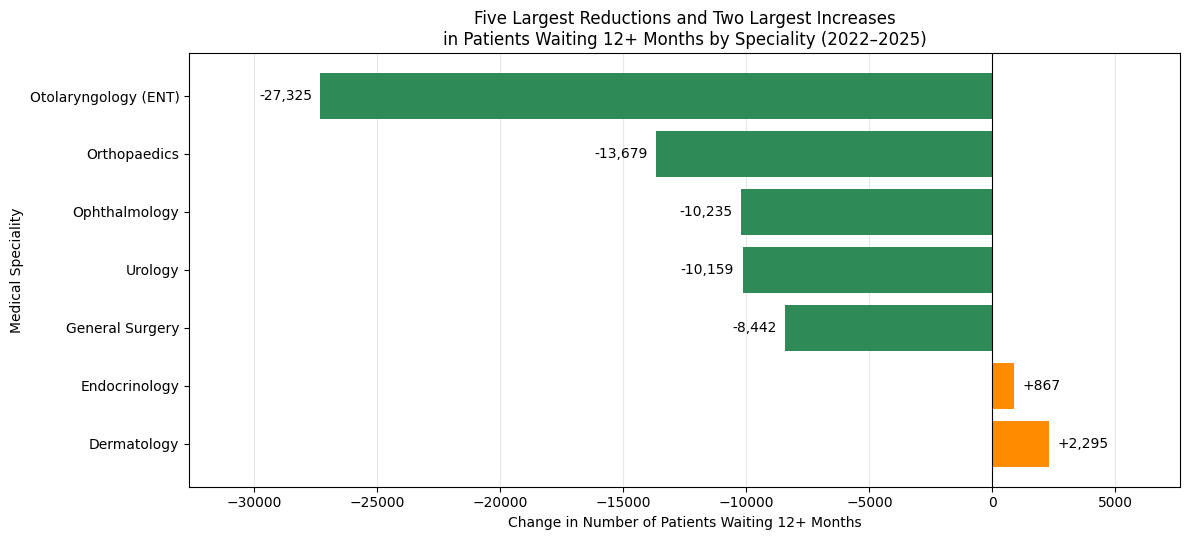

In [96]:

# Select five largest decreases and two largest increases

top_specialities = pd.concat([
    speciality_detail.nsmallest(5, 'Change in 12+ Patients'),
    speciality_detail.nlargest(2, 'Change in 12+ Patients')
]).sort_values('Change in 12+ Patients')

# Assign colours
colours = [
    'seagreen' if value < 0 else 'darkorange'
    for value in top_specialities['Change in 12+ Patients']
]

# Create chart
fig, ax = plt.subplots(figsize=(12, 5.5))

bars = ax.barh(
    top_specialities.index,
    top_specialities['Change in 12+ Patients'],
    color=colours
)

# Add value labels
for bar, value in zip(
    bars, top_specialities['Change in 12+ Patients']
):
    ax.annotate(
        f'{value:+,.0f}',
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(6 if value >= 0 else -6, 0),
        textcoords='offset points',
        va='center',
        ha='left' if value >= 0 else 'right'
    )

ax.axvline(0, color='black', linewidth=0.8)
ax.invert_yaxis()
ax.margins(x=0.18)

plt.title(
    'Five Largest Reductions and Two Largest Increases\n'
    'in Patients Waiting 12+ Months by Speciality (2022–2025)'
)

plt.xlabel('Change in Number of Patients Waiting 12+ Months')
plt.ylabel('Medical Speciality')

plt.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Findings**

Of the 55 medical specialities represented in both reporting periods, 46 (84%) recorded a reduction in the proportion of patients waiting 12 months or longer.

Otolaryngology (ENT) recorded the largest absolute reduction (27,325 patients), followed by Orthopaedics (13,679) and Ophthalmology (10,235). The five specialities with the largest reductions recorded a combined decrease of 69,840 long-waiting patients, equivalent to approximately 55% of the national net reduction.

However, Dermatology and Endocrinology recorded increases of 2,295 and 867 long-waiting patients respectively. Interestingly, both specialities recorded reductions in their proportions waiting 12 months or longer despite increases in actual patient numbers.

These findings highlight the uneven distribution of longer-wait reductions across medical specialities and demonstrate why patient counts should be considered alongside percentages. The analysis identifies where changes occurred but does not establish their underlying causes.

### 4.7 Supplementary Analysis: Demand and Outpatient Capacity

To explore possible factors associated with changes in outpatient waiting lists, supplementary data from HSE reports were examined.

Annual additions and removals were compared to assess changes in waiting-list demand and activity. Outpatient attendances and consultant staffing levels were also examined to provide context on changes in healthcare capacity between 2022 and 2025.

These indicators may help explain the national trends identified earlier, although they cannot establish direct causal relationships.

**Sources:** HSE *Waiting List Action Plan End of Year Reports 2024 and 2025*; Department of Health healthcare activity and staffing statistics.

In [97]:

# Annual outpatient waiting-list additions and removals
# Source: HSE Waiting List Action Plan End of Year Reports
# Figures are approximate and rounded to the nearest thousand

opd_activity = pd.DataFrame({
    'Year': [2022, 2023, 2024, 2025],
    'Additions': [1053000, 1180000, 1254000, 1336000],
    'Removals': [1086000, 1202000, 1259000, 1281000]
})

# Calculate the net change in waiting-list numbers
opd_activity['Net Change'] = (
    opd_activity['Additions'] -
    opd_activity['Removals']
)

# Display the results
display(opd_activity)


,Year,Additions,Removals,Net Change
0,2022,1053000,1086000,-33000
1,2023,1180000,1202000,-22000
2,2024,1254000,1259000,-5000
3,2025,1336000,1281000,55000


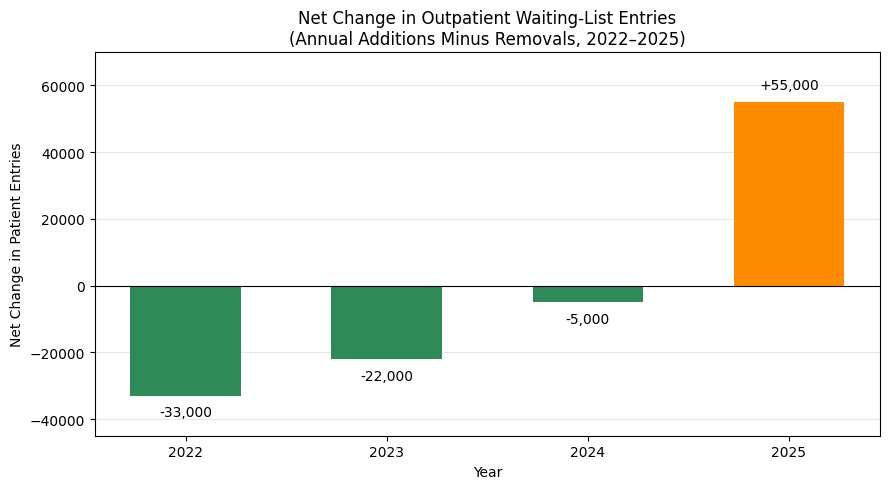

In [99]:

# Visualise annual net outpatient waiting-list activity

# Negative = more removals than additions
# Positive = more additions than removals

colours = [
    'seagreen' if value < 0 else 'darkorange'
    for value in opd_activity['Net Change']
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    opd_activity['Year'].astype(str),
    opd_activity['Net Change'],
    color=colours,
    width=0.55
)

# Add net change labels to each bar
for bar, value in zip(bars, opd_activity['Net Change']):
    ax.annotate(
        f'{value:+,}',
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 7 if value >= 0 else -7),
        textcoords='offset points',
        ha='center',
        va='bottom' if value >= 0 else 'top'
    )

# Add reference line at zero
ax.axhline(0, color='black', linewidth=0.8)

plt.title(
    'Net Change in Outpatient Waiting-List Entries\n'
    '(Annual Additions Minus Removals, 2022–2025)'
)
plt.xlabel('Year')
plt.ylabel('Net Change in Patient Entries')

plt.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

# Allow additional space for the value labels
ax.set_ylim(-45000, 70000)

plt.tight_layout()
plt.show()


**Findings**

Between 2022 and 2024, outpatient waiting-list removals exceeded additions, although the annual net reduction decreased from approximately 33,000 in 2022 to 5,000 in 2024.

In 2025, this pattern reversed, with approximately 55,000 more additions than removals, suggesting increasing pressure on overall outpatient waiting-list numbers.

This provides context for the national trends identified earlier. Although the number of patients waiting 12 months or longer declined substantially between January 2022 and December 2025, additions and removals indicate that managing overall waiting-list volumes remained challenging.

However, annual net activity does not explain changes in waiting duration directly, as it does not distinguish between shorter and longer waits.

#### Outpatient Activity and Consultant Staffing

To provide further context for changes in outpatient waiting times, annual outpatient attendances and consultant staffing levels were examined between 2022 and 2025.

Both indicators were converted into an index with 2022 as the baseline (100), allowing their relative growth to be compared despite differences in measurement units.

This comparison explores whether increased service activity and staffing coincided with improvements in longer outpatient waits, without assuming a direct causal relationship.

In [100]:

# Annual outpatient attendances (new and return appointments)
# Sources: Department of Health and HSE

outpatient_attendances = pd.DataFrame({
    'Year': [2022, 2023, 2024, 2025],
    'Attendances': [3410687, 3654786, 3981080, 4120220]
})

# Consultant staffing in whole-time equivalents (WTE)
# Source: Department of Health - Health in Ireland: Key Trends

consultant_staffing = pd.DataFrame({
    'Year': [2022, 2023, 2024, 2025],
    'Consultant WTE': [3869, 4246, 4601, 4858]
})

# Combine the two datasets by year
capacity_data = outpatient_attendances.merge(
    consultant_staffing,
    on='Year'
)

# Create index values using 2022 as the baseline (100)
capacity_data['Attendance Index'] = (
    capacity_data['Attendances'] /
    capacity_data['Attendances'].iloc[0] * 100
)

capacity_data['Consultant Index'] = (
    capacity_data['Consultant WTE'] /
    capacity_data['Consultant WTE'].iloc[0] * 100
)

# Calculate overall percentage increases
attendance_growth = capacity_data['Attendance Index'].iloc[-1] - 100
consultant_growth = capacity_data['Consultant Index'].iloc[-1] - 100

# Display results
display(capacity_data.round(2))

print(f"Increase in outpatient attendances: {attendance_growth:.2f}%")
print(f"Increase in consultant staffing: {consultant_growth:.2f}%")


,Year,Attendances,Consultant WTE,Attendance Index,Consultant Index
0,2022,3410687,3869,100.00,100.00
1,2023,3654786,4246,107.16,109.74
2,2024,3981080,4601,116.72,118.92
3,2025,4120220,4858,120.80,125.56


Increase in outpatient attendances: 20.80%
Increase in consultant staffing: 25.56%


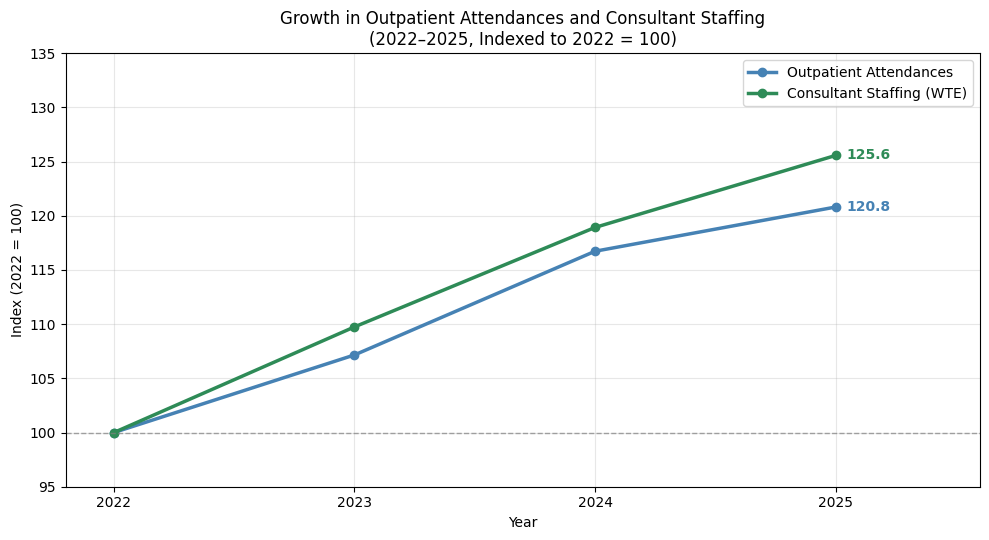

In [101]:

# Compare relative growth in outpatient attendances and consultant staffing

fig, ax = plt.subplots(figsize=(10, 5.5))

# Plot outpatient attendances
ax.plot(
    capacity_data['Year'],
    capacity_data['Attendance Index'],
    marker='o',
    linewidth=2.5,
    color='steelblue',
    label='Outpatient Attendances'
)

# Plot consultant staffing
ax.plot(
    capacity_data['Year'],
    capacity_data['Consultant Index'],
    marker='o',
    linewidth=2.5,
    color='seagreen',
    label='Consultant Staffing (WTE)'
)

# Add baseline reference
ax.axhline(
    100,
    color='grey',
    linestyle='--',
    linewidth=1,
    alpha=0.7
)

# Label final index values
for column, colour in [
    ('Attendance Index', 'steelblue'),
    ('Consultant Index', 'seagreen')
]:
    value = capacity_data[column].iloc[-1]

    ax.annotate(
        f'{value:.1f}',
        xy=(2025, value),
        xytext=(8, 0),
        textcoords='offset points',
        va='center',
        color=colour,
        fontweight='bold'
    )

# Format graph
ax.set_xticks(capacity_data['Year'])
ax.set_xlim(2021.8, 2025.6)
ax.set_ylim(95, 135)

plt.title(
    'Growth in Outpatient Attendances and Consultant Staffing\n'
    '(2022–2025, Indexed to 2022 = 100)'
)

plt.xlabel('Year')
plt.ylabel('Index (2022 = 100)')

plt.legend()
plt.grid(alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Findings**

Between 2022 and 2025, outpatient attendances increased by 20.8%, while consultant staffing increased by 25.6%. Both indicators showed consistent growth throughout the period.

This suggests an expansion in healthcare activity and staffing alongside the substantial reduction in patients waiting 12 months or longer identified earlier in the analysis.

Increased service capacity may have contributed to improved access to outpatient care. However, these figures do not establish a direct relationship between staffing growth and reduced waiting times. Outpatient attendances include both new and return appointments, while consultant staffing reflects the wider public hospital service rather than outpatient services alone.

The findings therefore provide useful context for the waiting-list improvements, but should be interpreted as possible contributing factors rather than evidence of causation.

**Potential Contributing Factors**

The increase in outpatient activity and consultant staffing coincided with national initiatives aimed at reducing waiting times. The 2024 Waiting List Action Plan included proposals to expand consultant-led clinics, while the HSE introduced modernised care pathways to improve access to specialist services.

According to the HSE (2025), these pathways delivered 186,986 outpatient appointments and removed 28,414 patients from outpatient waiting lists during 2024. Initiatives covered specialities including Orthopaedics, Urology, Ophthalmology, Dermatology and Endocrinology.

These measures provide plausible explanations for some of the improvements observed between 2022 and 2025. However, their individual contribution to the reductions identified in this analysis cannot be established from the available data.

**Sources:**

- Department of Health (2024). [*Minister Donnelly publishes the Waiting List Action Plan for 2024*](https://www.gov.ie/en/department-of-health/press-releases/minister-donnelly-publishes-the-waiting-list-action-plan-for-2024/).
- HSE (2025). [*Reduced hospital visits and waiting time for patients*](https://about.hse.ie/news/reduced-hospital-visits-and-waiting-time-for-patients/).

### 4.8 Dashboard Summary

A static dashboard was created using Matplotlib to bring together the key findings of the analysis.

It summarises national waiting-list trends, changes in waiting-time distribution, adult and child comparisons, and selected performance indicators. The dashboard provides an overview of how outpatient waiting lists changed between 2022 and 2025.

In [ ]:

# DASHBOARD SUMMARY

# Calculate key statistics for the dashboard
first_period = monthly_hospital.iloc[0]
last_period = monthly_hospital.iloc[-1]

total_change = (
    (last_period['Total'] - first_period['Total'])
    / first_period['Total'] * 100
)

long_wait_change = (
    last_period['12+ Percent'] - first_period['12+ Percent']
)

hospitals_decreased = (hospital_changes['Change (pp)'] < 0).sum()
hospitals_compared = len(hospital_changes)

# Create dashboard with four charts
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

fig.suptitle(
    'Irish Public Hospital Outpatient Waiting Lists (2022–2025)',
    fontsize=17,
    fontweight='bold',
    y=0.98
)


# Display four key statistics across the top of the dashboard

kpis = [
    (
        'PATIENTS WAITING',
        f"{last_period['Total']:,.0f}",
        f'{total_change:+.2f}% since Jan 2022'
    ),
    (
        'WAITING 12+ MONTHS',
        f"{last_period['12+ Percent']:.2f}%",
        f'{long_wait_change:+.2f} percentage points'
    ),
    (
        'HOSPITALS WITH A DECREASE',
        f'{hospitals_decreased}/{hospitals_compared}',
        'In 12+ month waiting percentage'
    ),
    (
        '2025 NET ADDITIONS',
        f"{opd_activity.loc[
            opd_activity['Year'] == 2025,
            'Net Change'
        ].iloc[0]:+,}",
        'Approximate HSE annual figure'
    )
]

# Position the four indicators
positions = [0.06, 0.30, 0.54, 0.78]

for x, (heading, value, description) in zip(positions, kpis):
    fig.text(x, 0.90, heading, fontsize=9)
    fig.text(x, 0.855, value, fontsize=19, fontweight='bold')
    fig.text(x, 0.825, description, fontsize=8)


# Chart 1: National waiting-list totals
axes[0, 0].plot(
    monthly_hospital['ArchiveDate'],
    monthly_hospital['Total']
)
axes[0, 0].set_title('National Waiting-List Totals')
axes[0, 0].set_ylabel('Patients Waiting')
axes[0, 0].grid(alpha=0.3)

# Chart 2: Percentage waiting 12+ months
axes[0, 1].plot(
    monthly_hospital['ArchiveDate'],
    monthly_hospital['12+ Percent'],
    color='darkorange'
)
axes[0, 1].set_title('Proportion Waiting 12+ Months')
axes[0, 1].set_ylabel('Percentage (%)')
axes[0, 1].grid(alpha=0.3)

# Chart 3: Waiting-time distribution
waiting_percent.plot(
    kind='bar',
    stacked=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Waiting-Time Distribution')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('Percentage (%)')
axes[1, 0].set_ylim(0, 100)
axes[1, 0].tick_params(axis='x', rotation=0)
axes[1, 0].legend(title='Waiting Period', fontsize=8)

# Chart 4: Adult vs Child comparison
adult_child_percent[['Jan 2022', 'Dec 2025']].plot(
    kind='bar',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Adults vs Children Waiting 12+ Months')
axes[1, 1].set_xlabel('')
axes[1, 1].set_ylabel('Percentage (%)')
axes[1, 1].tick_params(axis='x', rotation=0)
axes[1, 1].legend(title='Reporting Period')
axes[1, 1].grid(axis='y', alpha=0.3)

# Format dashboard
for ax in axes[0]:
    ax.tick_params(axis='x', rotation=30)

fig.text(
    0.5, 0.02,
    'Sources: NTPF outpatient waiting-list snapshots (2022–2025); '
    'HSE Waiting List Action Plan End of Year Reports.',
    ha='center',
    fontsize=9
)

plt.tight_layout(rect=[0.02, 0.06, 0.98, 0.79])
plt.show()


The dashboard highlights the difference between overall waiting-list numbers and the proportion of patients experiencing longer waits.

Although the total waiting list decreased by only 2.16% between January 2022 and December 2025, the number waiting 12 months or longer fell by 55.98%. Improvements were evident across both adult and child waiting lists and in most hospitals.

However, the positive net additions recorded in 2025 demonstrate that demand remains a challenge.

Overall, the dashboard reinforces the importance of considering waiting-time distribution alongside total waiting-list numbers when assessing outpatient waiting-list performance.

## 5. DISCUSSION

The analysis identified a substantial change in the distribution of outpatient waiting times in Irish public hospitals between January 2022 and December 2025. Although the total number of patients waiting decreased by only 2.16%, the number waiting 12 months or longer fell by 55.98%. This suggests that the overall size of the waiting list does not necessarily reflect changes in how long patients have been waiting.

One of the most significant findings was the shift towards shorter waiting-time categories. The number of patients waiting less than 12 months increased by approximately 113,910, while those waiting 12 months or longer decreased by 127,442. This helps explain how the overall waiting list remained relatively stable despite the substantial reduction in longer waits. These findings are consistent with the OECD's *Country Health Profile 2025: Ireland*, which also identified reductions in longer waiting times alongside continued pressure on outpatient waiting lists.

However, the improvements were not consistent across all hospitals and specialities. Of the 43 hospitals represented in both reporting periods, 34 recorded a reduction in the proportion waiting 12 months or longer, while nine recorded an increase. Similarly, 46 of the 55 matched specialities recorded a reduction. This demonstrates that national figures can conceal considerable differences between individual hospitals and medical specialities.

Additional HSE data provides some insight into why waiting-list numbers remained high. Between 2022 and 2024, annual outpatient removals exceeded additions, but this pattern reversed in 2025, when approximately 55,000 more patients were added than removed. This helps explain the increase in waiting-list numbers during 2025 and supports the Department of Health's observation that increasing demand continues to place pressure on planned care services.

Population growth may also have contributed to demand. However, the population-adjusted waiting-list rate remained relatively similar between December 2022 and December 2025. The sharper increase during 2025 suggests that population growth alone is unlikely to explain the changes observed.

Outpatient attendances increased by 20.80% between 2022 and 2025, while consultant staffing increased by 25.56%. This indicates that hospital staffing and outpatient activity expanded during the period. Although increased activity may have contributed to reducing longer waits, the available data cannot establish a direct causal relationship.

### Limitations

The NTPF datasets contain monthly snapshots rather than individual patient records. Therefore, the analysis cannot determine how long individual patients eventually waited or establish why patients entered or left waiting lists.

Comparisons between hospitals and specialities may also be affected by differences in patient volumes and reporting categories. In addition, the consultant staffing figures cover the wider public hospital service, while outpatient attendances include both new and return appointments.

The analysis therefore identifies trends and possible contributing factors, rather than proving the causes of changes in outpatient waiting times.

## 6. CONCLUSION

This analysis examined outpatient waiting-list trends in Irish public hospitals between January 2022 and December 2025, focusing on changes in patient numbers, waiting-time categories and differences across hospitals, specialities and patient groups.

The findings show that although the overall waiting list decreased by only 2.16%, the number of patients waiting 12 months or longer decreased by 55.98%. This demonstrates that changes in the total waiting-list size alone do not provide a complete picture of outpatient waiting times.

The reduction in longer waits was observed across both adult and child waiting lists and in most hospitals and medical specialities. However, improvements were not consistent across all areas, with some hospitals and specialities recording increases in the proportion waiting 12 months or longer.

Additional analysis identified increasing outpatient demand, population growth and expanded outpatient activity and consultant staffing. While these factors provide possible explanations for the trends observed, the available data cannot establish a direct causal relationship.

Overall, the analysis demonstrates substantial progress in reducing longer outpatient waits between 2022 and 2025, despite continued pressure on waiting-list numbers. The findings highlight the importance of monitoring both the number of patients waiting and the length of time they have been waiting when evaluating outpatient access to healthcare in Ireland.

## 7. REFERENCES

Central Statistics Office (2025). *Population and Migration Estimates, April 2025*. Available at: https://www.cso.ie/en/releasesandpublications/ep/p-pme/populationandmigrationestimatesapril2025/

Department of Health (2026). *Health in Ireland: Key Trends – Hospital Care*. Available at: https://www.gov.ie/en/department-of-health/publications/health-in-ireland-key-trends-hospital-care/

Department of Health (2026). *Health in Ireland: Key Trends – Health Service Employment*. Available at: https://www.gov.ie/en/department-of-health/publications/health-in-ireland-key-trends-health-service-employment/

Department of Health (2026). *Waiting Time Action Plan 2026*. Available at: https://www.gov.ie/en/department-of-health/publications/waiting-time-action-plan-2026/

Health Service Executive (2025). *2024 Waiting List Action Plan End of Year Report*. Available at: https://www.hse.ie/eng/about/who/acute-hospitals-division/waiting-list-action-plans/2024-waiting-list-action-plan-end-of-year-report.pdf

Health Service Executive (2026). *Waiting List Action Plan 2025 – End of Year Report*. Available at: https://about.hse.ie/publications/waiting-list-action-plan-2025-end-of-year-report/

Health Service Executive (2026). *Management Data Report – December 2025*. Available at: https://www.drugsandalcohol.ie/43574/

National Treatment Purchase Fund (2026). *Open Data*. Available at: https://www.ntpf.ie/waiting-list-data/open-data/

OECD/European Observatory on Health Systems and Policies (2025). *Country Health Profile 2025: Ireland*. Paris: OECD Publishing. Available at: https://www.oecd.org/content/dam/oecd/en/publications/reports/2025/12/country-health-profile-2025-country-notes_7e72146d/ireland_6304dfa1/c879341f-en.pdf

*All sources accessed: 13 November 2026.*